# Plant Disease Classification Using Deep Learning & Vision Transformers
## Production Colab Runner (GPU Acceleration & Fault-Tolerant Training)

This notebook is configured to run automatically (**Runtime → Run All**) with:
- **Project Root**: `FOLDER_ROOT = '/content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification'`
- **Raw Data Directory**: `DataDir = '/content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/raw'`
- **Data Splits**: `SplitDir = '/content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split'`
- **Kaggle API Integration**: Automated credentials setup from Colab `userdata` (Secrets) matching `01_data_audit.ipynb`.
- **Fault-Tolerant Auto-Resume & Auto-Skip**: Recovers model, optimizer, scheduler from `last_checkpoint.pth` upon reconnect.



### 1. Mount Google Drive & Set Working Directory


In [19]:

import os
import sys
from pathlib import Path

# 1. Detect the execution environment
IS_COLAB = "google.colab" in sys.modules

if not IS_COLAB:
    try:
        import google.colab
        IS_COLAB = True
    except ImportError:
        IS_COLAB = False

# 2. Configure the project root
if IS_COLAB:
    from google.colab import drive

    # Mount Google Drive
    drive.mount("/content/drive")

    FOLDER_ROOT = Path(
        "/content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification"
    )

    # Search for the project if the default path does not exist
    if not FOLDER_ROOT.is_dir():
        drive_root = Path("/content/drive/MyDrive")
        candidates = [
            p for p in drive_root.rglob("PlantDiseaseClassification")
            if p.is_dir()
        ]

        if candidates:
            FOLDER_ROOT = candidates[0]

else:
    # Local environment: use the notebook's current directory
    FOLDER_ROOT = Path.cwd().resolve()

    # Search parent directories if the notebook is inside a subfolder
    for parent in [FOLDER_ROOT, *FOLDER_ROOT.parents]:
        if (parent / "src").is_dir() and (
            parent / "configs"
        ).is_dir():
            FOLDER_ROOT = parent
            break

# 3. Validate the project root
if not FOLDER_ROOT.is_dir():
    raise FileNotFoundError(
        f"Project root does not exist: {FOLDER_ROOT}"
    )

print(f"Environment : {'Google Colab' if IS_COLAB else 'Local'}")
print(f"Project Root: {FOLDER_ROOT}")

# 4. Set the working directory and Python import path
os.chdir(FOLDER_ROOT)

if str(FOLDER_ROOT) not in sys.path:
    sys.path.insert(0, str(FOLDER_ROOT))

print(f"Working Dir : {Path.cwd()}")

Mounted at /content/drive
Environment : Google Colab
Project Root: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification
Working Dir : /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification


### 2. Check GPU Diagnostics & Install Dependencies


In [2]:
!nvidia-smi
!pip install -q -r requirements.txt

Fri Oct 30 11:28:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 3. Configure Kaggle Credentials from Secrets (Colab Userdata)


In [3]:
import os
try:
    from google.colab import userdata
    username = userdata.get('KAGGLE_USERNAME')
    token = userdata.get('KAGGLE_API_TOKEN')
    if username:
        os.environ['KAGGLE_USERNAME'] = username
    if token:
        os.environ['KAGGLE_API_TOKEN'] = token
    print('Kaggle credentials configured from Colab Secrets.')
except Exception as err:
    print(f'Notice: {err}. If dataset already exists in data/raw, credentials are not required.')



Notice: Requesting secret KAGGLE_USERNAME timed out. Secrets can only be fetched when running from the Colab UI.. If dataset already exists in data/raw, credentials are not required.


### 4. Verify Environment, Paths, Dataset & Splits (Dry Run)


In [4]:
# Run pre-flight dry run verification
!python colab_train.py --dry_run



🌐 [ENVIRONMENT] Google Colab Runtime Detected
⚠️ [COLAB] Notice: Google Drive mount skipped or failed (type object 'TermColors' has no attribute 'Green')
📂 [FOLDER_ROOT] Project Root: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification
📁 [DATA_DIR]    Raw Data:     /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/raw
📊 [SPLIT_DIR]   Data Split:   /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split
📊 [TRAIN CSV] Path: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split/train.csv (Exists: True)
📊 [VAL CSV]   Path: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split/val.csv   (Exists: True)
📊 [TEST CSV]  Path: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split/test.csv  (Exists: True)
⬇️ [DATASET] Dataset not found in data/raw. Initiating download via Kaggle API...
ℹ️ [KAGGLE] Userdata lookup note: type object 'TermColors' has no attribute 'Green'


### 5. Train ResNet-50 Baseline (CNN Benchmark)


In [5]:
# Train ResNet-50 with auto-resume enabled
!python colab_train.py --model_name resnet50



🌐 [ENVIRONMENT] Google Colab Runtime Detected
⚠️ [COLAB] Notice: Google Drive mount skipped or failed (type object 'TermColors' has no attribute 'Green')
📂 [FOLDER_ROOT] Project Root: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification
📁 [DATA_DIR]    Raw Data:     /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/raw
📊 [SPLIT_DIR]   Data Split:   /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split
📊 [TRAIN CSV] Path: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split/train.csv (Exists: True)
📊 [VAL CSV]   Path: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split/val.csv   (Exists: True)
📊 [TEST CSV]  Path: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split/test.csv  (Exists: True)
🌿 [DATASET] Found existing color dataset at: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/raw/plantvillage dataset/color

🚀 [EXPERIMENT] Ru

### 6. Train Vision Transformer (ViT-Base/16)


In [6]:
# Train ViT-Base with gradient accumulation (effective batch size = 32)
!python colab_train.py --model_name vit_base_patch16_224



🌐 [ENVIRONMENT] Google Colab Runtime Detected
⚠️ [COLAB] Notice: Google Drive mount skipped or failed (type object 'TermColors' has no attribute 'Green')
📂 [FOLDER_ROOT] Project Root: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification
📁 [DATA_DIR]    Raw Data:     /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/raw
📊 [SPLIT_DIR]   Data Split:   /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split
📊 [TRAIN CSV] Path: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split/train.csv (Exists: True)
📊 [VAL CSV]   Path: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split/val.csv   (Exists: True)
📊 [TEST CSV]  Path: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split/test.csv  (Exists: True)
🌿 [DATASET] Found existing color dataset at: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/raw/plantvillage dataset/color

🚀 [EXPERIMENT] Ru

### 7. Train EfficientNet-B0 Baseline


In [7]:
# Train EfficientNet-B0
!python colab_train.py --model_name efficientnet_b0



🌐 [ENVIRONMENT] Google Colab Runtime Detected
⚠️ [COLAB] Notice: Google Drive mount skipped or failed (type object 'TermColors' has no attribute 'Green')
📂 [FOLDER_ROOT] Project Root: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification
📁 [DATA_DIR]    Raw Data:     /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/raw
📊 [SPLIT_DIR]   Data Split:   /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split
📊 [TRAIN CSV] Path: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split/train.csv (Exists: True)
📊 [VAL CSV]   Path: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split/val.csv   (Exists: True)
📊 [TEST CSV]  Path: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split/test.csv  (Exists: True)
🌿 [DATASET] Found existing color dataset at: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/raw/plantvillage dataset/color

🚀 [EXPERIMENT] Ru

### 8. Optional: Run All Benchmark Models Sequentially


In [8]:
# Sequentially trains ResNet-50 -> ViT-Base -> EfficientNet-B0 with Auto-Skip
!python colab_train.py --all



🌐 [ENVIRONMENT] Google Colab Runtime Detected
⚠️ [COLAB] Notice: Google Drive mount skipped or failed (type object 'TermColors' has no attribute 'Green')
📂 [FOLDER_ROOT] Project Root: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification
📁 [DATA_DIR]    Raw Data:     /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/raw
📊 [SPLIT_DIR]   Data Split:   /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split
📊 [TRAIN CSV] Path: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split/train.csv (Exists: True)
📊 [VAL CSV]   Path: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split/val.csv   (Exists: True)
📊 [TEST CSV]  Path: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/split/test.csv  (Exists: True)
🌿 [DATASET] Found existing color dataset at: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/data/raw/plantvillage dataset/color

🎯 [PIPELINE] Sequ

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (

Experiment: efficientnet_b0   ->   GOOD AND STABLE
Best val loss: 0.0129 at epoch 10 | final val loss: 0.0129 (+0.0%)
Final train acc (proxy): 0.9996 | final val macro-F1: 0.9944 | gap: +0.0052
Like-for-like accuracy gap (train_acc - val_acc): +0.0039
  - GOOD AND STABLE: val macro-F1 0.9944, std over last 3 epochs 0.0004. Positive signal, but NOT proof of generalization: confirm on the frozen test set and, ideally, on out-of-distribution (in-the-wild) images.
Figure saved: /content/drive/MyDrive/Home/10_Projects/PlantDiseaseClassification/outputs/figures/efficientnet_b0_learning_curves.png

Experiment: resnet50   ->   GOOD AND STABLE
Best val loss: 0.0386 at epoch 10 | final val loss: 0.0386 (+0.0%)
Final train acc (proxy): 0.9963 | final val macro-F1: 0.9859 | gap: +0.0104
Lik

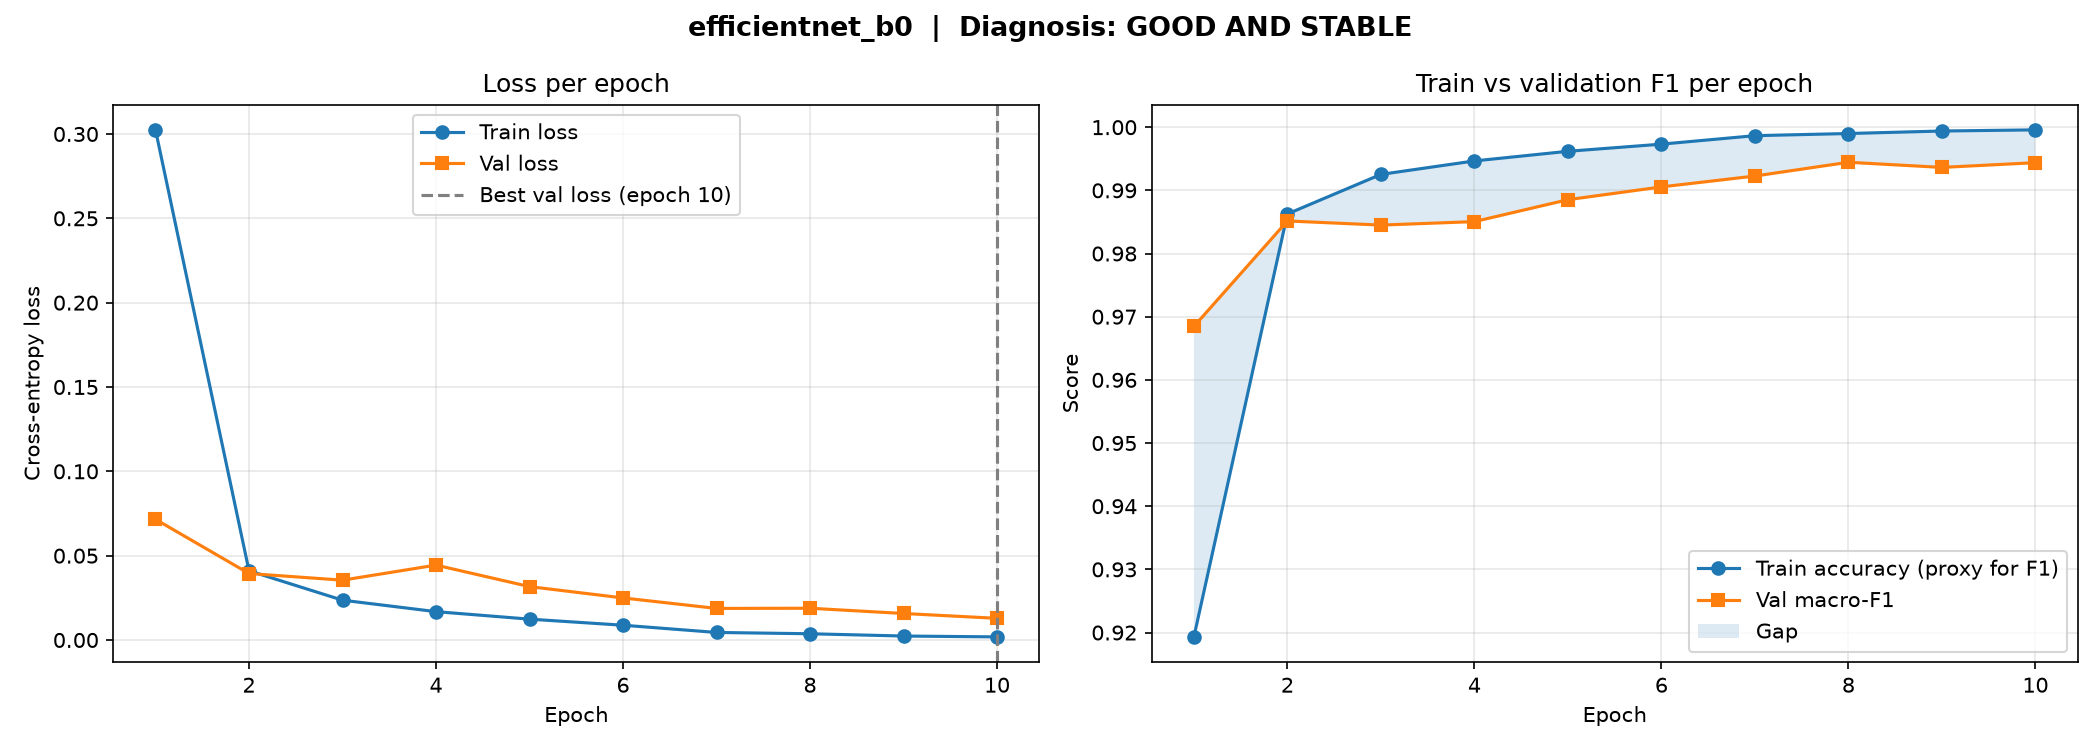

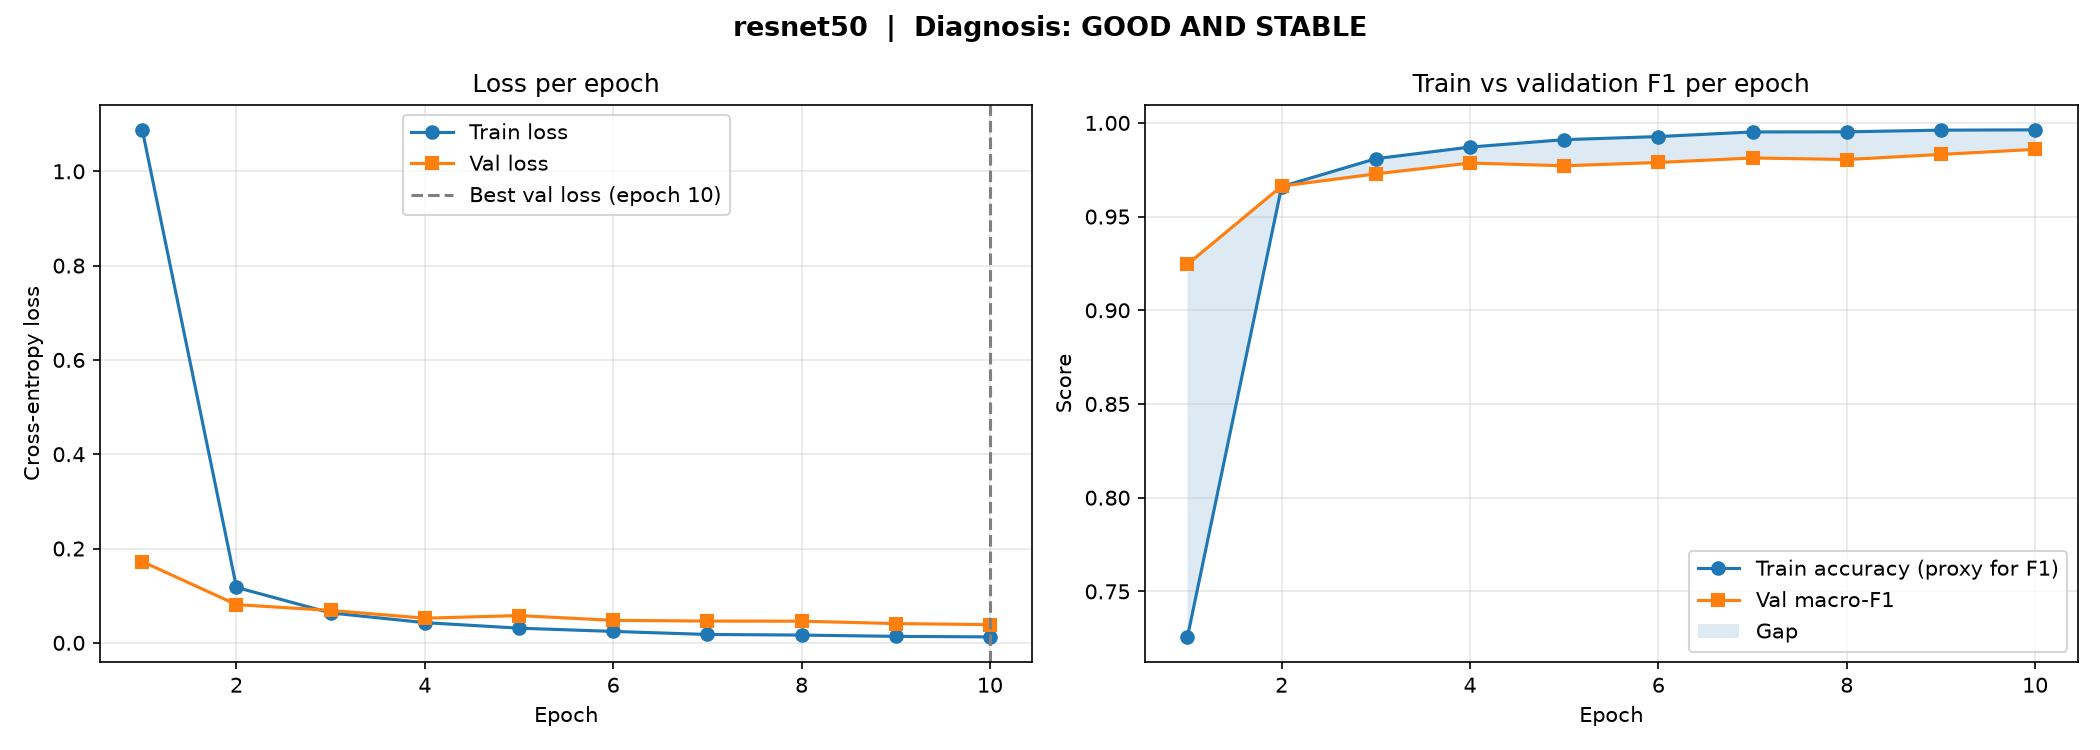

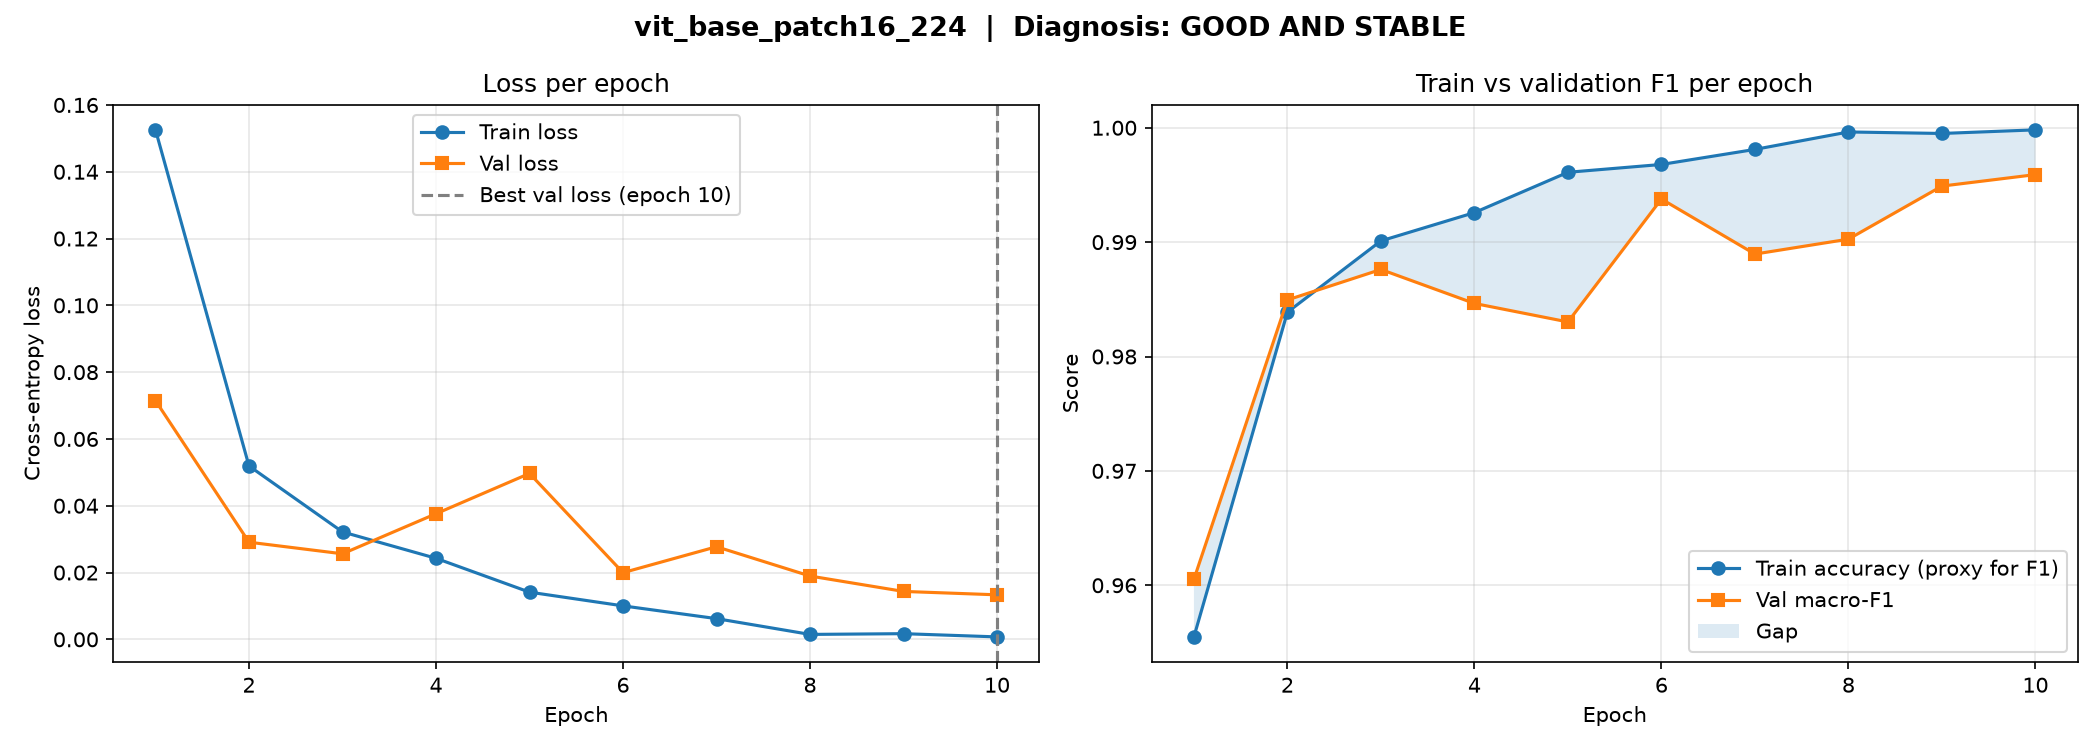

In [9]:
import glob
from IPython.display import Image, display

EVAL_TRAIN_F1 = False   # True: evaluate best checkpoints on the train split (exact train macro-F1)

DATA_ROOT = f"{FOLDER_ROOT}/data/raw/plantvillage dataset/color"
extra = f'--eval_train_f1 --data_root "{DATA_ROOT}"' if EVAL_TRAIN_F1 else ""
!python scripts/plot_training_curves.py {extra}

for fig in sorted(glob.glob("outputs/figures/*_learning_curves.png")):
    display(Image(filename=fig))

In [10]:
!git config --global user.email "thanhdt942@gmail.com"
!git config --global user.name "Tan Thanh"

In [11]:
!git add .

!git commit -m "Update code from collab"

!git push origin master

^C
On branch master
Your branch is up to date with 'origin/master'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   colab_train.py
	modified:   notebooks/colab_train.ipynb
	modified:   src/train.py
	modified:   train.py

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	outputs/checkpoints/
	outputs/figures/efficientnet_b0_learning_curves.png
	outputs/figures/resnet50_learning_curves.png
	outputs/figures/vit_base_patch16_224_learning_curves.png
	outputs/logs/
	outputs/tables/
	scripts/

no changes added to commit (use "git add" and/or "git commit -a")
Everything up-to-date
